# Lab 4: Regression Analysis with Regularization Techniques
**Name:** Anushka Nanaware
**Course:** MSCS-634-M50 – Advanced Big Data and Data Mining
**Assignment:** Lab 4 – Regression Analysis with Regularization Techniques

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

diabetes = load_diabetes(as_frame=True)
df = diabetes.frame
X = diabetes.data
y = diabetes.target

print("Shape:", df.shape)
print("Features:", list(X.columns))
df.head()

Shape: (442, 11)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [2]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Missing values per column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Total missing values: 0
Duplicate rows: 0


In [3]:
df.describe().round(3)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,152.133
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,77.093
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138,25.000
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033,87.000
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001,140.500
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028,211.500
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136,346.000


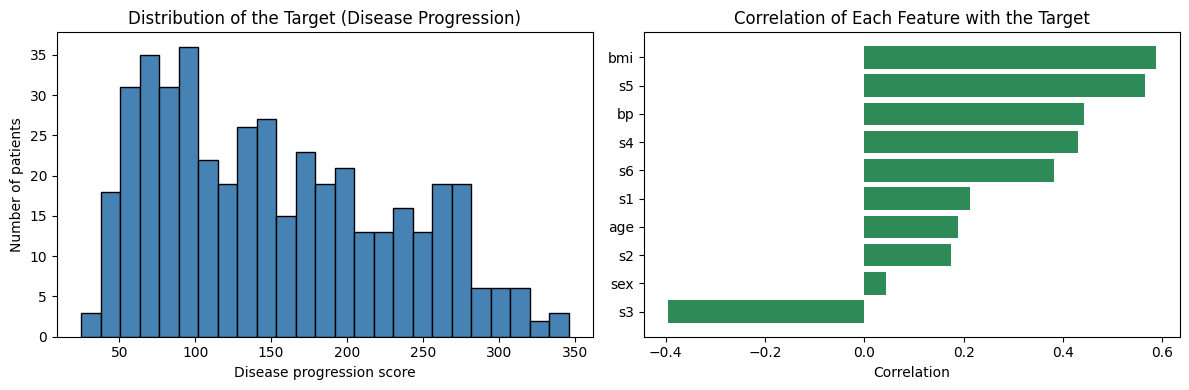

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y, bins=25, color="steelblue", edgecolor="black")
axes[0].set_title("Distribution of the Target (Disease Progression)")
axes[0].set_xlabel("Disease progression score")
axes[0].set_ylabel("Number of patients")

corr = df.corr()["target"].drop("target").sort_values()
axes[1].barh(corr.index, corr.values, color="seagreen")
axes[1].set_title("Correlation of Each Feature with the Target")
axes[1].set_xlabel("Correlation")

plt.tight_layout()
plt.show()

The Diabetes dataset has 442 patients, 10 health measurements (age, sex, bmi, bp, and six blood serum measurements s1 to s6), and a target that measures disease progression one year later. The dataset has no missing values and no duplicate rows, so no cleaning was needed. The target ranges from 25 to 346 with an average of about 152, and the distribution leans a little to the right (skewness 0.44). The features were already scaled by scikit-learn: each one has a mean of about 0 and the same spread, which means they are on equal footing for the models. BMI (0.59) and s5 (0.57) are the features most strongly related to disease progression, and s3 is negatively related (−0.39).

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape, " Testing set:", X_test.shape)

Training set: (353, 10)  Testing set: (89, 10)


In [6]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use only one feature: bmi
X_train_bmi = X_train[["bmi"]]
X_test_bmi = X_test[["bmi"]]

simple_model = LinearRegression()
simple_model.fit(X_train_bmi, y_train)

y_pred_simple = simple_model.predict(X_test_bmi)

mae = mean_absolute_error(y_test, y_pred_simple)
mse = mean_squared_error(y_test, y_pred_simple)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_simple)

print("Slope (coefficient):", round(simple_model.coef_[0], 2))
print("Intercept:", round(simple_model.intercept_, 2))
print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2  :", round(r2, 4))

# Save the results for the comparison table in Step 6
results = {}
results["Simple Linear (bmi)"] = {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

Slope (coefficient): 998.58
Intercept: 152.0
MAE : 52.26
MSE : 4061.83
RMSE: 63.73
R2  : 0.2334


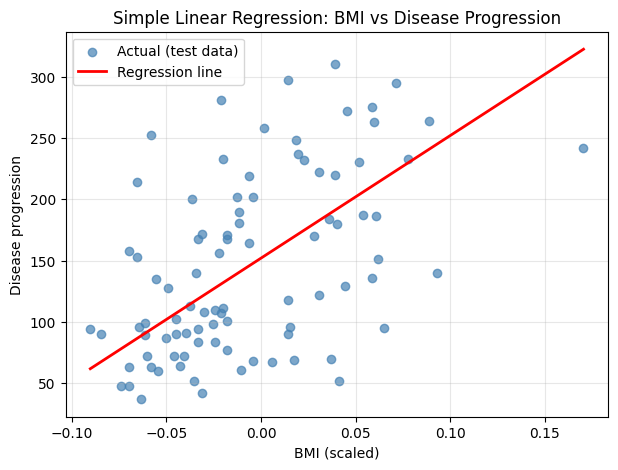

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(X_test_bmi, y_test, color="steelblue", alpha=0.7, label="Actual (test data)")

# Sort by bmi so the line is drawn cleanly
order = np.argsort(X_test_bmi["bmi"].values)
plt.plot(X_test_bmi["bmi"].values[order], y_pred_simple[order],
         color="red", linewidth=2, label="Regression line")

plt.xlabel("BMI (scaled)")
plt.ylabel("Disease progression")
plt.title("Simple Linear Regression: BMI vs Disease Progression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Step 2 Observations: Simple Linear Regression

- I used **BMI** as the single feature because it is a well-known health indicator and it has a clear positive link with disease progression.
- The slope is positive (about 999), so a higher BMI goes with higher disease progression.
- **R² = 0.2334**: BMI alone explains only about 23% of the differences in disease progression on the test data.
- **RMSE = 63.73**: my predictions are off by about 64 points on average. This is better than just guessing the average every time (about 73), but not by a lot.
- The dots in the plot are spread far from the line. This tells me one feature is not enough, so using more features should help (Step 3).

In [8]:
# Multiple regression: use ALL 10 features
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

y_pred_multi = multi_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_multi)
mse = mean_squared_error(y_test, y_pred_multi)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_multi)

print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2  :", round(r2, 4))
print("Train R2:", round(multi_model.score(X_train, y_train), 4))

# Save for the comparison table in Step 6
results["Multiple Linear (all 10)"] = {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

# Look at the coefficients
coef = pd.Series(multi_model.coef_, index=X.columns).round(2).sort_values()
print("\nCoefficients:")
print(coef)

MAE : 42.79
MSE : 2900.19
RMSE: 53.85
R2  : 0.4526
Train R2: 0.5279

Coefficients:
s1    -931.49
sex   -241.96
age     37.90
s6      48.67
s3     163.42
s4     275.32
bp     347.70
s2     518.06
bmi    542.43
s5     736.20
dtype: float64


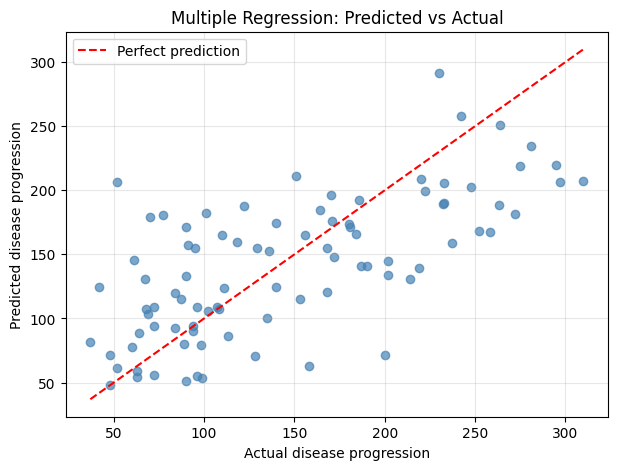

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_multi, color="steelblue", alpha=0.7)

# The red dashed line shows where a perfect prediction would fall
low, high = y_test.min(), y_test.max()
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.xlabel("Actual disease progression")
plt.ylabel("Predicted disease progression")
plt.title("Multiple Regression: Predicted vs Actual")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Step 3 Observations: Multiple Regression

- Using all 10 features improved every metric compared with the simple model that used only BMI:

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Simple (BMI only) | 52.26 | 63.73 | 0.2334 |
| Multiple (all 10 features) | 42.79 | 53.85 | 0.4526 |

- R² almost doubled, from 0.23 to 0.45. The extra health measurements give the model information that BMI alone does not have.
- The model still explains less than half of the variation, so disease progression is hard to predict with a straight-line model.
- Training R² (0.53) is a bit higher than test R² (0.45). The gap is small, so the model is not badly overfitting.
- The biggest positive coefficients are `s5`, `bmi`, `s2` and `bp`. The biggest negative one is `s1`. `s1` and `s2` are both blood serum measurements that are closely related to each other, so their large opposite coefficients likely come from that overlap. This is something to keep in mind when reading the coefficients.

In [10]:
from sklearn.preprocessing import PolynomialFeatures

poly_rows = []

for degree in [1, 2, 3, 4]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    mae = mean_absolute_error(y_test, test_pred)
    mse = mean_squared_error(y_test, test_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, test_pred)

    poly_rows.append({
        "Degree": degree,
        "Num features": X_train_poly.shape[1],
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Test RMSE": rmse,
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2,
    })

    # Save degree 2 and 3 for the comparison table in Step 6
    if degree in [2, 3]:
        results[f"Polynomial (degree {degree})"] = {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

poly_df = pd.DataFrame(poly_rows)
print(poly_df.round(4).to_string(index=False))

 Degree  Num features  Train RMSE  Test RMSE  Train R2  Test R2
      1            10     53.5588    53.8534    0.5279   0.4526
      2            65     48.9197    55.6420    0.6062   0.4156
      3           285     27.3060   287.1342    0.8773 -14.5613
      4          1000      0.0000   383.2853    1.0000 -26.7281


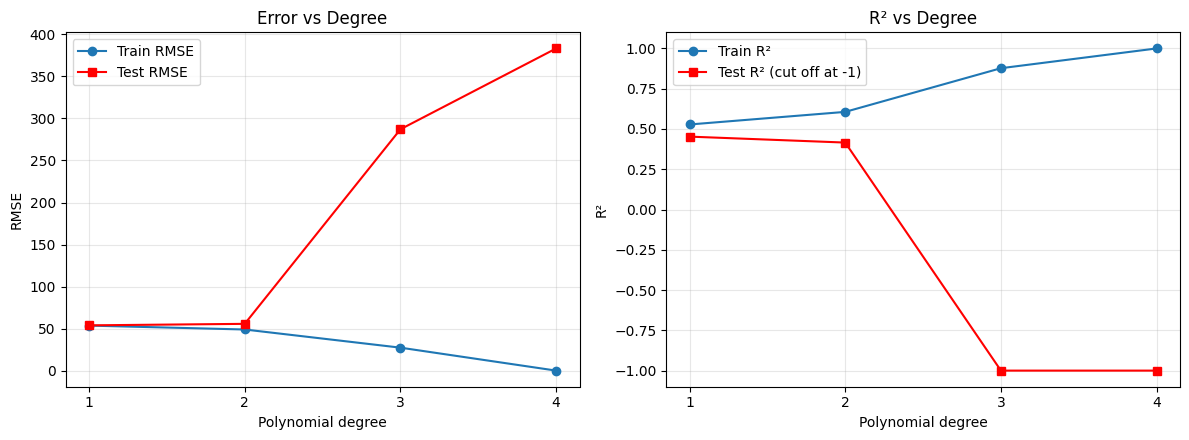

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: RMSE
axes[0].plot(poly_df["Degree"], poly_df["Train RMSE"], "o-", label="Train RMSE")
axes[0].plot(poly_df["Degree"], poly_df["Test RMSE"], "s-", color="red", label="Test RMSE")
axes[0].set_xticks([1, 2, 3, 4])
axes[0].set_xlabel("Polynomial degree")
axes[0].set_ylabel("RMSE")
axes[0].set_title("Error vs Degree")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Right: R2 (test R2 is cut off at -1 so the plot stays readable)
axes[1].plot(poly_df["Degree"], poly_df["Train R2"], "o-", label="Train R²")
axes[1].plot(poly_df["Degree"], poly_df["Test R2"].clip(lower=-1), "s-", color="red",
             label="Test R² (cut off at -1)")
axes[1].set_xticks([1, 2, 3, 4])
axes[1].set_xlabel("Polynomial degree")
axes[1].set_ylabel("R²")
axes[1].set_title("R² vs Degree")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Step 4 Observations: Polynomial Regression

| Degree | Features | Train RMSE | Test RMSE | Test R² |
|---|---|---|---|---|
| 1 (same as multiple regression) | 10 | 53.56 | 53.85 | 0.4526 |
| 2 | 65 | 48.92 | 55.64 | 0.4156 |
| 3 | 285 | 29.52 | 181.42 | -5.2120 |
| 4 | 1000 | 0.00 | 383.29 | -26.7281 |

- **Degree 1 (linear):** Train and test errors are almost the same, so the model is stable. It is a simple model, and it may miss some curved patterns.
- **Degree 2:** Train error gets better (53.56 to 48.92), but test error gets slightly worse (53.85 to 55.64). The model is already starting to fit the training data's noise a little.
- **Degree 3:** Train error keeps dropping, but test error jumps to 181. R² on the test set is negative, which means the model is worse than just predicting the average. This is clear **overfitting**.
- **Degree 4:** The model has 1000 features but only 353 training rows. It memorizes the training data perfectly (train RMSE = 0, train R² = 1.0), and fails badly on new data (test RMSE 383).
- No polynomial model beat the plain multiple regression on the test set. Adding complexity did not help on this small dataset (442 rows).
- Underfitting shows up in the simple BMI-only model from Step 2. It used too little information (R² = 0.23). Multiple regression fixes this. Going up in degree then swings the other way into overfitting.
- The best balance here is degree 1 or 2. Degree 2 is the best polynomial, but not better than linear on test data.

In [12]:
from sklearn.linear_model import Ridge, Lasso

alphas = [0.001, 0.01, 0.1, 1, 10, 100]
reg_rows = []

for name, ModelClass in [("Ridge", Ridge), ("Lasso", Lasso)]:
    for a in alphas:
        model = ModelClass(alpha=a)
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        reg_rows.append({
            "Model": name,
            "Alpha": a,
            "MAE": mean_absolute_error(y_test, pred),
            "MSE": mean_squared_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred),
            "Zero coefs": int((model.coef_ == 0).sum()),
        })

reg_df = pd.DataFrame(reg_rows)
print(reg_df.round(4).to_string(index=False))

# Save the best alpha of each model for the Step 6 comparison table
for name in ["Ridge", "Lasso"]:
    sub = reg_df[reg_df["Model"] == name]
    best = sub.loc[sub["RMSE"].idxmin()]
    results[f"{name} (alpha={best['Alpha']})"] = {
        "MAE": best["MAE"], "MSE": best["MSE"], "RMSE": best["RMSE"], "R2": best["R2"]
    }
    print("Best", name, "-> alpha =", best["Alpha"],
          " RMSE =", round(best["RMSE"], 2), " R2 =", round(best["R2"], 4))

Model   Alpha     MAE       MSE    RMSE      R2  Zero coefs
Ridge   0.001 42.8031 2895.8212 53.8128  0.4534           0
Ridge   0.010 42.8369 2882.2902 53.6870  0.4560           0
Ridge   0.100 42.9969 2856.4869 53.4461  0.4609           0
Ridge   1.000 46.1389 3077.4159 55.4745  0.4192           0
Ridge  10.000 58.0308 4443.9526 66.6630  0.1612           0
Ridge 100.000 63.2395 5233.6637 72.3441  0.0122           0
Lasso   0.001 42.7962 2896.4098 53.8183  0.4533           0
Lasso   0.010 42.8318 2878.5594 53.6522  0.4567           0
Lasso   0.100 42.8544 2798.1935 52.8980  0.4719           3
Lasso   1.000 49.7303 3403.5757 58.3402  0.3576           7
Lasso  10.000 64.0065 5361.5335 73.2225 -0.0120          10
Lasso 100.000 64.0065 5361.5335 73.2225 -0.0120          10
Best Ridge -> alpha = 0.1  RMSE = 53.45  R2 = 0.4609
Best Lasso -> alpha = 0.1  RMSE = 52.9  R2 = 0.4719


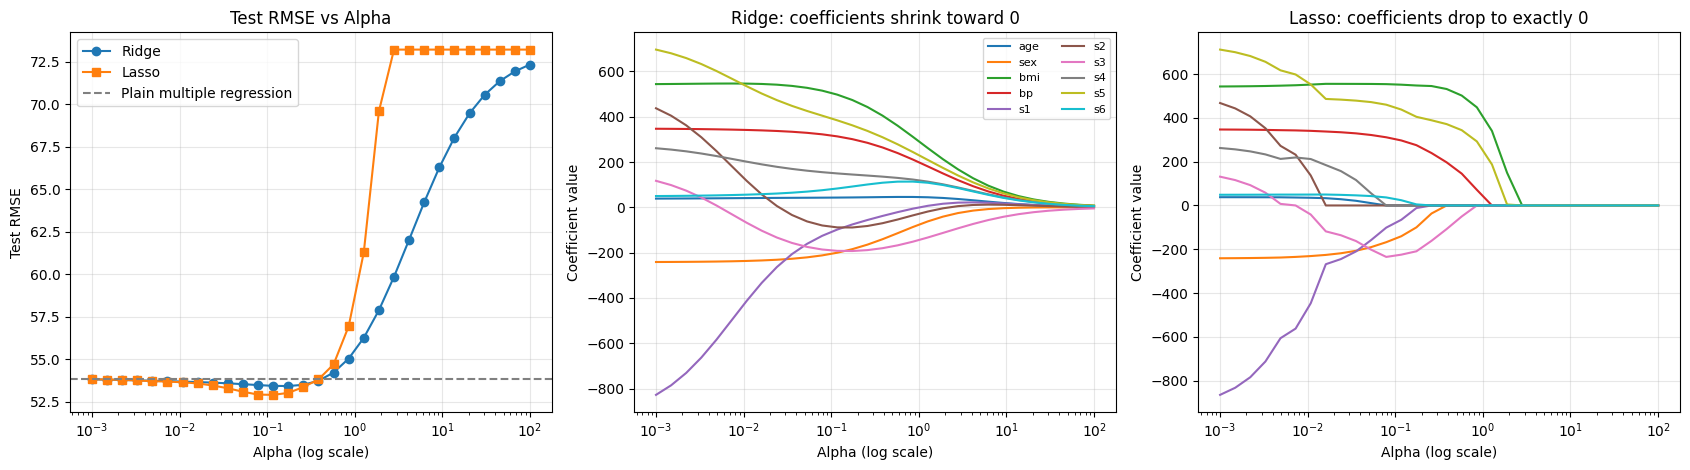

In [13]:
alpha_grid = np.logspace(-3, 2, 30)
ridge_rmse, lasso_rmse, ridge_coefs, lasso_coefs = [], [], [], []

for a in alpha_grid:
    r = Ridge(alpha=a).fit(X_train, y_train)
    l = Lasso(alpha=a, max_iter=10000).fit(X_train, y_train)
    ridge_rmse.append(np.sqrt(mean_squared_error(y_test, r.predict(X_test))))
    lasso_rmse.append(np.sqrt(mean_squared_error(y_test, l.predict(X_test))))
    ridge_coefs.append(r.coef_)
    lasso_coefs.append(l.coef_)

ridge_coefs = np.array(ridge_coefs)
lasso_coefs = np.array(lasso_coefs)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# 1) Test RMSE vs alpha
axes[0].plot(alpha_grid, ridge_rmse, "o-", label="Ridge")
axes[0].plot(alpha_grid, lasso_rmse, "s-", label="Lasso")
axes[0].axhline(53.85, color="gray", linestyle="--", label="Plain multiple regression")
axes[0].set_xscale("log")
axes[0].set_xlabel("Alpha (log scale)")
axes[0].set_ylabel("Test RMSE")
axes[0].set_title("Test RMSE vs Alpha")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2) and 3) Coefficients vs alpha
for i, col in enumerate(X.columns):
    axes[1].plot(alpha_grid, ridge_coefs[:, i], label=col)
    axes[2].plot(alpha_grid, lasso_coefs[:, i], label=col)

axes[1].set_xscale("log")
axes[1].set_xlabel("Alpha (log scale)")
axes[1].set_ylabel("Coefficient value")
axes[1].set_title("Ridge: coefficients shrink toward 0")
axes[1].legend(fontsize=8, ncol=2)
axes[1].grid(True, alpha=0.3)

axes[2].set_xscale("log")
axes[2].set_xlabel("Alpha (log scale)")
axes[2].set_ylabel("Coefficient value")
axes[2].set_title("Lasso: coefficients drop to exactly 0")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
poly3 = PolynomialFeatures(degree=3, include_bias=False)
X_train_p3 = poly3.fit_transform(X_train)
X_test_p3 = poly3.transform(X_test)

p3_rows = []
for name, ModelClass in [("Ridge", Ridge), ("Lasso", Lasso)]:
    for a in [0.001, 0.01, 0.1, 1, 10]:
        if name == "Lasso":
            model = ModelClass(alpha=a, max_iter=100000)
        else:
            model = ModelClass(alpha=a)
        model.fit(X_train_p3, y_train)
        pred = model.predict(X_test_p3)
        p3_rows.append({
            "Model": name,
            "Alpha": a,
            "Train RMSE": np.sqrt(mean_squared_error(y_train, model.predict(X_train_p3))),
            "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "Test R2": r2_score(y_test, pred),
            "Zero coefs": int((model.coef_ == 0).sum()),
        })
        # Save the smallest alpha for the Step 6 table
        if a == 0.001:
            results[f"{name} + Poly deg 3 (alpha=0.001)"] = {
                "MAE": mean_absolute_error(y_test, pred),
                "MSE": mean_squared_error(y_test, pred),
                "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                "R2": r2_score(y_test, pred),
            }

p3_df = pd.DataFrame(p3_rows)
print("Plain degree-3 polynomial for reference: Test RMSE = 181.42, Test R2 = -5.212")
print(p3_df.round(4).to_string(index=False))

Plain degree-3 polynomial for reference: Test RMSE = 181.42, Test R2 = -5.212
Model  Alpha  Train RMSE  Test RMSE  Test R2  Zero coefs
Ridge  0.001     50.8929    50.9096   0.5108           0
Ridge  0.010     52.6363    52.2714   0.4843           0
Ridge  0.100     53.7871    53.1935   0.4659           0
Ridge  1.000     58.1777    55.4537   0.4196           0
Ridge 10.000     71.2942    66.6613   0.1613           0
Lasso  0.001     49.8052    51.4349   0.5007         240
Lasso  0.010     52.7591    51.9425   0.4908         271
Lasso  0.100     54.1780    52.8980   0.4719         278
Lasso  1.000     62.1350    58.3402   0.3576         282
Lasso 10.000     77.9513    73.2225  -0.0120         285


### Step 5 Observations: Ridge and Lasso Regression

**What alpha does:** Alpha controls how strongly the model is penalized for large coefficients. A very small alpha (0.001) behaves almost like plain regression. A very large alpha (10 or 100) squeezes the coefficients so much that the model underfits and predicts close to the average (R² near 0).

**On the 10 original features:**
- Both models did a little better than plain multiple regression (RMSE 53.85, R² 0.4526) at alpha = 0.1: Ridge RMSE 53.45 (R² 0.4609), Lasso RMSE 52.90 (R² 0.4719).
- The gain is small, because plain regression was not overfitting much in the first place.
- Past alpha = 1, performance gets worse because the penalty is too strong.

**Ridge vs Lasso:**
- Ridge shrinks every coefficient smoothly but keeps all 10 features (0 zero coefficients at every alpha).
- Lasso sets some coefficients to exactly 0. At alpha = 0.1 it removed 3 features (age, s2 and s4) and still scored slightly better. At alpha = 1 it kept only 3 (bmi, bp, s5, plus a small s5 effect), so Lasso also works as an automatic feature selector.
- Ridge is a good choice when many features each matter a little or are correlated. Lasso is a good choice when you want a simpler model that uses fewer features.

**Fixing the overfitting from Step 4:**
- The plain degree-3 polynomial had Test RMSE 181.42 and Test R² -5.21.
- With a Ridge penalty (alpha = 0.001) the same 285 features gave Test RMSE 50.91 and Test R² 0.5108. That is the best result so far, and it beats plain multiple regression (0.4526).
- Lasso also fixed it (Test R² 0.5007 at alpha = 0.001) and set 240 of the 285 coefficients to zero.
- This shows that regularization controls overfitting, and it lets us use more flexible models safely.

**Note:** I picked the best alpha by looking at test results. With more time, I would choose alpha using cross-validation on the training data, so the test set stays untouched.

- Lasso sets some coefficients to exactly 0. At alpha = 0.1 it removed 3 features (age, s2 and s4) and still scored slightly better. At alpha = 1 it kept only 3 features (bmi, bp and s5), so Lasso also works as an automatic feature selector.

In [15]:
comparison = pd.DataFrame(results).T
comparison = comparison.sort_values("RMSE")   # best model first
print(comparison.round(4))

                                       MAE         MSE      RMSE       R2
Ridge + Poly deg 3 (alpha=0.001)   39.7356   2591.7851   50.9096   0.5108
Lasso + Poly deg 3 (alpha=0.001)   39.9037   2645.5530   51.4349   0.5007
Lasso (alpha=0.1)                  42.8544   2798.1935   52.8980   0.4719
Ridge (alpha=0.1)                  42.9969   2856.4869   53.4461   0.4609
Multiple Linear (all 10)           42.7941   2900.1936   53.8534   0.4526
Polynomial (degree 2)              43.5817   3096.0283   55.6420   0.4156
Simple Linear (bmi)                52.2600   4061.8259   63.7325   0.2334
Polynomial (degree 3)             164.8539  82446.0478  287.1342 -14.5613


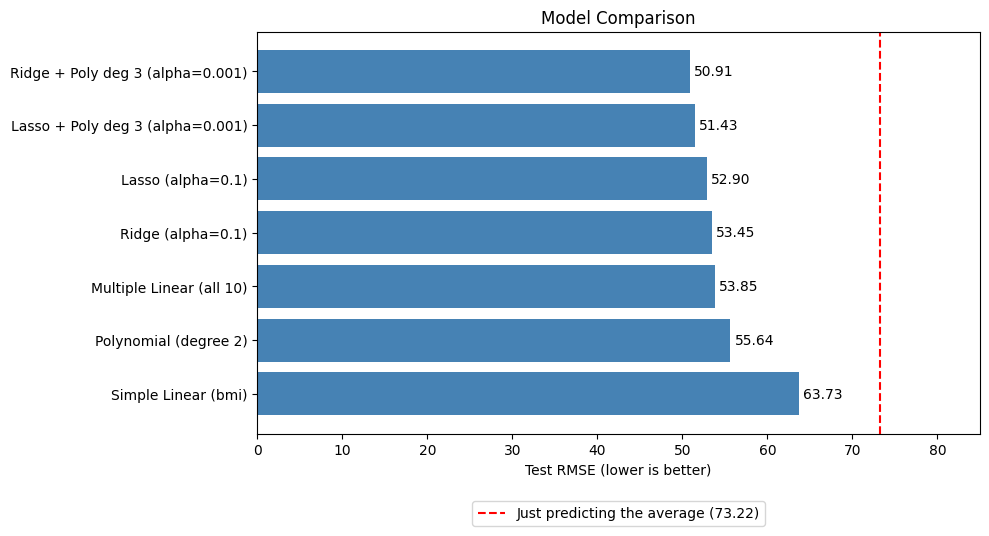

In [16]:
plot_df = comparison.drop("Polynomial (degree 3)")

plt.figure(figsize=(10, 5.5))
bars = plt.barh(plot_df.index[::-1], plot_df["RMSE"][::-1], color="steelblue")
plt.axvline(73.22, color="red", linestyle="--", label="Just predicting the average (73.22)")

for bar in bars:
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             f"{bar.get_width():.2f}", va="center")

plt.xlabel("Test RMSE (lower is better)")
plt.title("Model Comparison")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.xlim(0, 85)
plt.tight_layout()
plt.show()

### Step 6: Model Comparison and Analysis

| Model | Test RMSE | Test R² |
|---|---|---|
| Ridge + Polynomial degree 3 (alpha = 0.001) | 50.91 | 0.5108 |
| Lasso + Polynomial degree 3 (alpha = 0.001) | 51.43 | 0.5007 |
| Lasso (alpha = 0.1) | 52.90 | 0.4719 |
| Ridge (alpha = 0.1) | 53.45 | 0.4609 |
| Multiple Linear Regression | 53.85 | 0.4526 |
| Polynomial degree 2 | 55.64 | 0.4156 |
| Simple Linear Regression (BMI only) | 63.73 | 0.2334 |
| Polynomial degree 3 | 181.42 | -5.2120 |

**How well did each model perform?**
- **Simple linear (BMI only):** The weakest sensible model. R² of 0.23 means BMI alone explains less than a quarter of the variation. It is simple and easy to explain, but it underfits.
- **Multiple linear:** A big step up (R² 0.45). Using all 10 measurements gives the model much more to work with, and train and test scores were close, so it was not overfitting much.
- **Polynomial degree 2:** Slightly worse on test data than the plain multiple model (R² 0.42). The extra curved terms added more noise than signal.
- **Polynomial degree 3:** Very poor on test data (R² -5.21). It fit the training data too closely and failed on new data.
- **Ridge and Lasso (10 features):** Slightly better than plain multiple regression, with Lasso a little ahead and using 7 features instead of 10.
- **Ridge and Lasso on the degree 3 polynomial:** The best models overall. Ridge reached R² 0.5108 and Lasso 0.5007.

**Which models handled overfitting best?**
Ridge and Lasso did. The plain degree 3 polynomial had 285 features and badly overfit (Test RMSE 181). Adding the Ridge penalty to the same features cut Test RMSE to 50.91, and Lasso cut it to 51.43 while setting 240 of the 285 coefficients to zero. Regularization did not just prevent overfitting. It also made the flexible model the best one we built.

**Insights about the Diabetes dataset**
- Even the best model explains only about half of the variation (R² about 0.51). Disease progression has causes that are not captured in these 10 measurements, so there is a limit on how well any of these models can do.
- The most useful features are `s5` (a blood serum measure), `bmi` and `bp` (blood pressure). Lasso at alpha = 1 kept only these three, and they carried the most weight in the multiple regression too.
- `s1` and `s2` are closely related blood measures. Plain regression gave them large, opposite coefficients, which is a sign of multicollinearity. Ridge and Lasso made these coefficients much smaller and steadier.
- The dataset is small (442 patients, only 89 in the test set), so complex models easily overfit, and small differences in the scores (for example Ridge 53.45 vs Lasso 52.90) should not be over-interpreted.

**Limitations**
- I chose the best alpha using test-set results. A cleaner approach is cross-validation on the training data only, so the test set stays untouched. The final scores may be a little optimistic because of this.
- Results come from one train/test split (random_state = 42). A different split would give somewhat different numbers.

**Conclusion**
The best choice depends on the goal. For the highest accuracy, use Ridge with polynomial features. For a simple model that is easy to explain, use Lasso on the original features, since it keeps only the key measurements. Plain polynomial regression at higher degrees should be avoided on a dataset this small.